# Proyecto Final DL — LoRA vs Fine-tuning completo vs Prompting (tweets en español)
Runtime: **GPU T4** (Entorno de ejecución → Cambiar tipo → T4). Tiempo total estimado: 1.5–2.5 h.
Los resultados se guardan en Google Drive para sobrevivir desconexiones; `run_all.py` es idempotente (salta lo ya hecho).

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs('/content/drive/MyDrive/dl_results', exist_ok=True)

Mounted at /content/drive


In [12]:
REPO_URL = "https://github.com/Ultimate-Truth-Seeker/ProyectoFinalDL.git"
!git clone $REPO_URL /content/proyecto 2>/dev/null || (cd /content/proyecto && git pull)
%cd /content/proyecto
!rm -rf results && ln -s /content/drive/MyDrive/dl_results results
!pip install -q "datasets>=2.20,<4.0" peft accelerate evaluate shap tabulate
!pip install --upgrade torchao

Already up to date.
/content/proyecto
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 73.4 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


## Prueba rápida (1 corrida LoRA, ~3 min) antes de lanzar todo

In [13]:
!python -m src.finetune --task tweets --mode lora --seed 99 --epochs 2 --out /content/smoke

Map: 100% 870/870 [00:00<00:00, 10360.69 examples/s]
Loading weights: 100% 197/197 [00:00<00:00, 4562.05it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your d

## Experimento completo
Prompting (zero/few-shot) → full FT vs LoRA (5 semillas tweets, 3 en news) → ablación LoRA → agregación → SHAP.

In [14]:
!python run_all.py

config.json: 100% 660/660 [00:00<00:00, 2.25MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 18.8MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 74.3MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 123MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 142MB/s]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

model.safetensors: downloading bytes:   0% 9.84M/3.09G [00:00<04:19, 11.9MB/s]
model.safetensors: downloading bytes:   6% 172M/3.09G [00:01<00:14, 203MB/s, 13.6MB/s  ]
model.safetensors: downloading bytes:   7% 201M/3.09G [00:01<00:16, 177MB/s, 17.5MB/s  ]
model.safetensors: reconstructing file:   0% 13.7M/3.09G [00:01<05:23, 9.50MB/s,  752kB/s  ]
model.safetensors: reconstructing file:   1% 19.6M/3.09G [00:02<03:28, 14.7MB/s, 1.30MB/s  ]
model.safetensors: downloading bytes:   7% 225M/3.09G [00:02<00:21, 132MB/s, 19.9MB/s  ]
model.safetensors: downloading bytes:  11% 348M/3.09G [00:03<00:18, 148MB/s, 26.6MB/s  ]
model.safetensors: downloading bytes: 

## Resultados

|                           |   n_seeds | test_acc      | test_macroF1   |   params_entrenables |   %_del_total |   mem_pico_MB |   tiempo_s |
|:--------------------------|----------:|:--------------|:---------------|---------------------:|--------------:|--------------:|-----------:|
| ('news', 'full')          |         3 | 0.898 ± 0.004 | 0.897 ± 0.004  |            278052876 |        100    |          5367 |      422   |
| ('news', 'lora_r8_qv')    |         3 | 0.889 ± 0.006 | 0.886 ± 0.006  |               894732 |          0.32 |          2521 |       59.5 |
| ('tweets', 'full')        |         5 | 0.673 ± 0.008 | 0.667 ± 0.012  |            278045955 |        100    |          5358 |      421.6 |
| ('tweets', 'lora_r16_qv') |         3 | 0.678 ± 0.016 | 0.674 ± 0.017  |              1182723 |          0.42 |          1859 |       34.1 |
| ('tweets', 'lora_r2_qv')  |         3 | 0.669 ± 0.014 | 0.663 ± 0.019  |               666627 |          0.24 |          1851 |       33.6 |

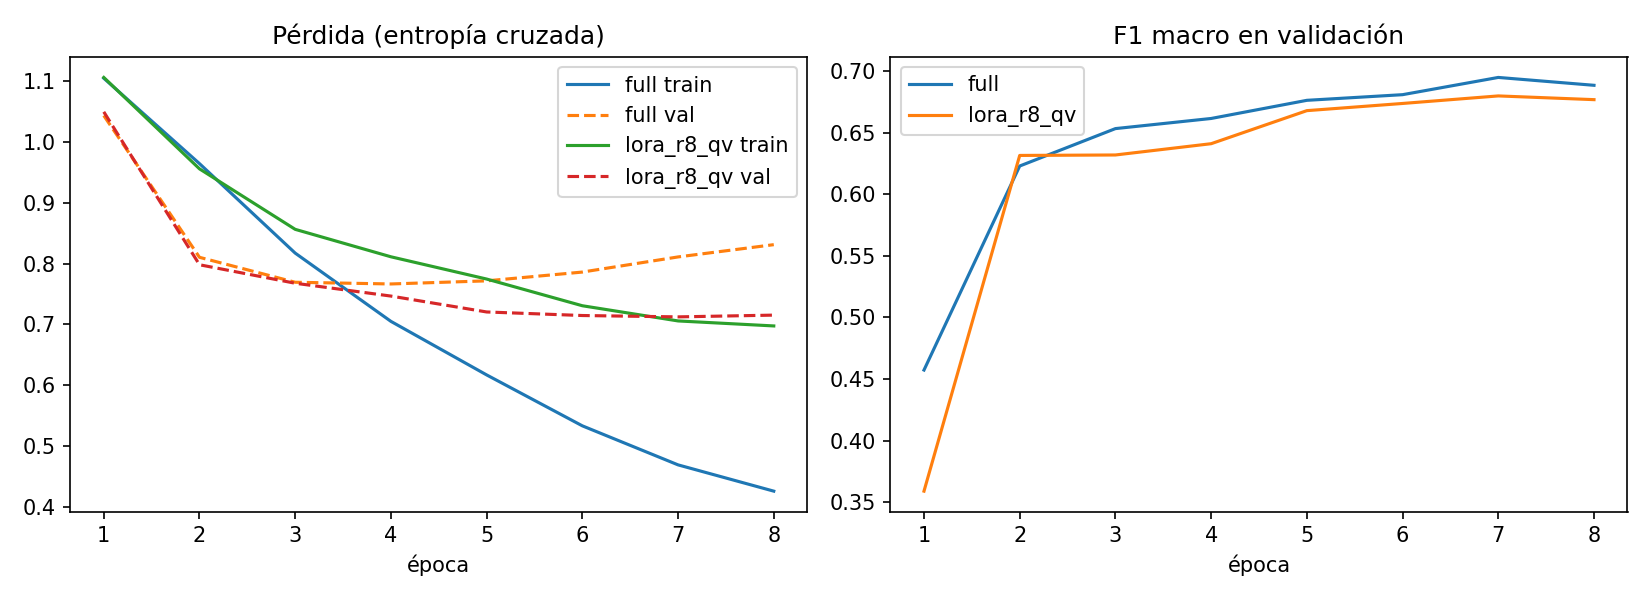

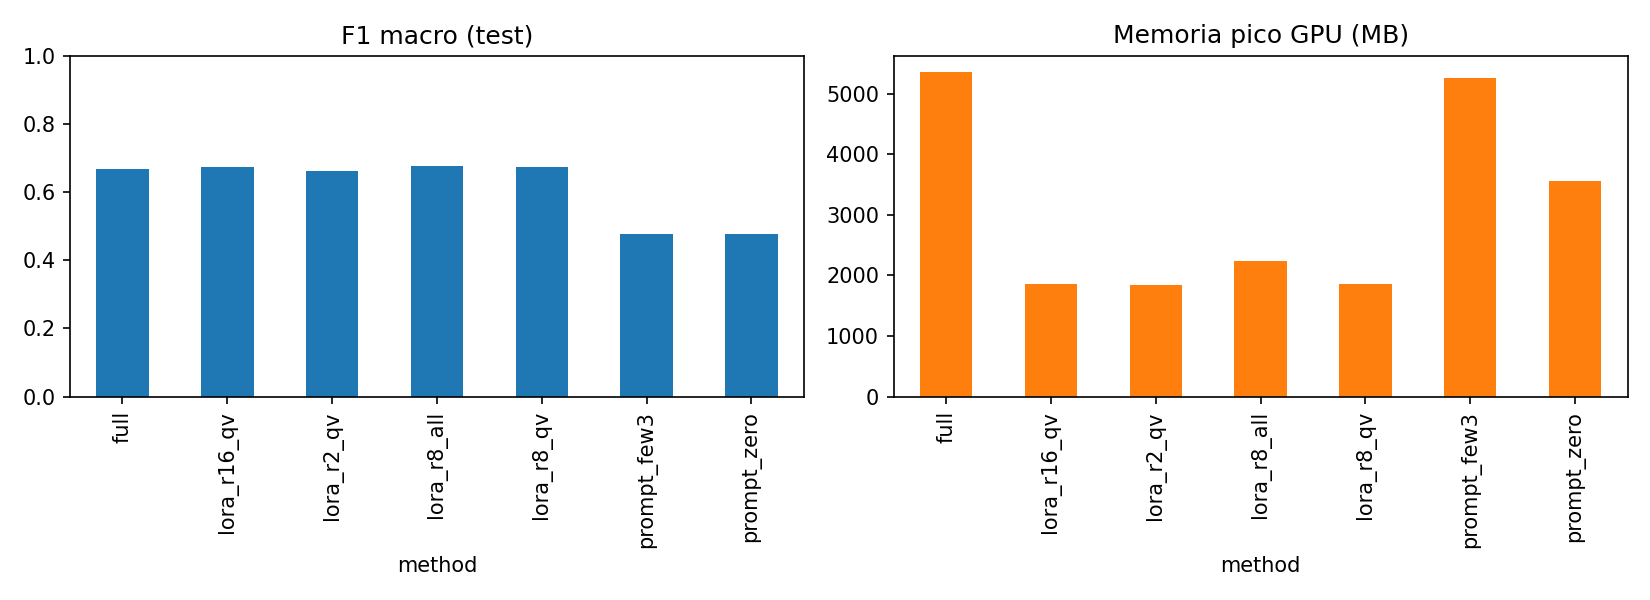

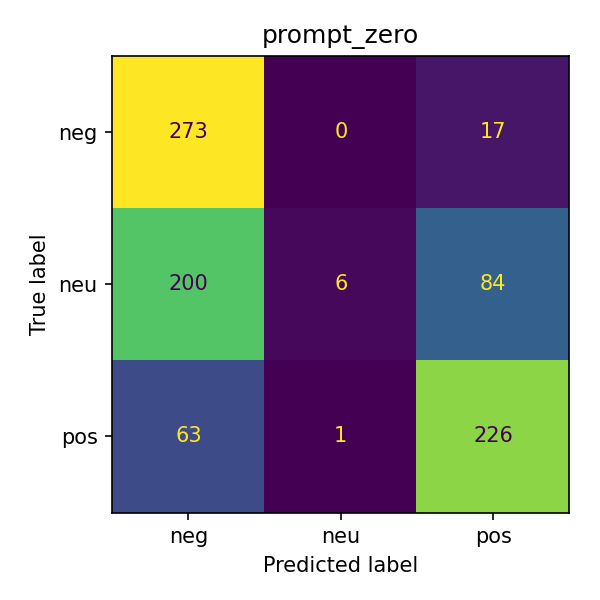

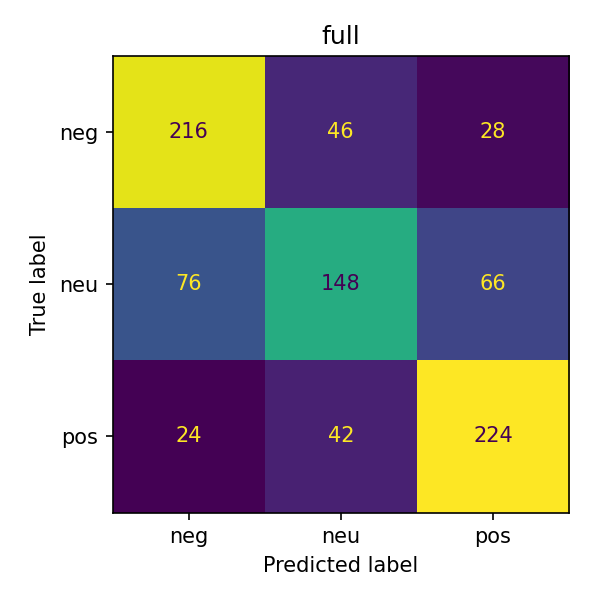

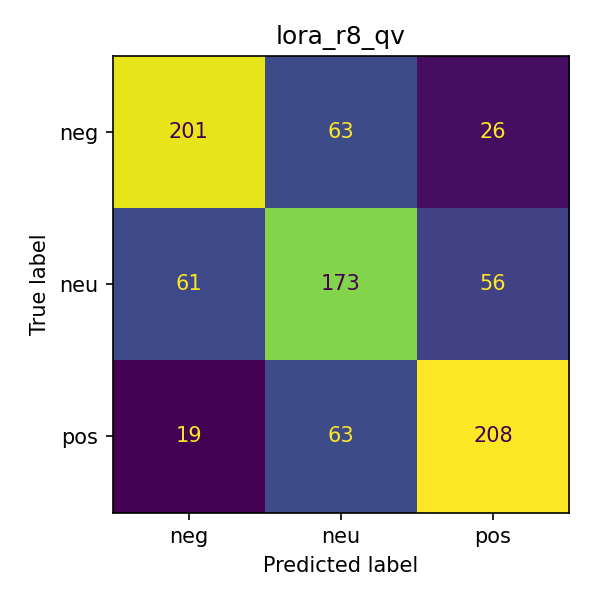

In [15]:
import pandas as pd
from IPython.display import Image, display, HTML
print(open('results/tabla_comparativa.md').read())
for f in ['curvas_entrenamiento','f1_memoria','cm_prompt_zero','cm_full','cm_lora_r8_qv']:
    display(Image(f'figures/{f}.png'))

## Explicabilidad (SHAP) — errores del modelo LoRA

In [16]:
display(pd.read_csv('results/explain/ejemplos.csv').head(20))
print('Palabras que más empujan hacia la clase predicha en ERRORES:')
display(pd.read_csv('results/explain/palabras_errores.csv').head(15))
display(HTML(open('results/explain/shap_text.html').read()))

,idx,texto,real,pred,correcto
0,131,Cuando no sepas que hacer nada mas hagarra tu ...,positive,neutral,False
1,520,#2añosdelegiónholk Un año antes no me imagine ...,neutral,positive,False
2,226,Me despierto a las 6 de lo más tranquilo y rel...,neutral,negative,False
3,613,"@user Yo soy tu sangre mi viejo, yooo, soy tu ...",neutral,positive,False
4,840,Es gracioso cuando intentan sacarte del medio ...,negative,positive,False
5,107,@user ya era hora de volver al csgo y dejares ...,positive,neutral,False
6,288,Cómo es eso que te extraño? Tamaaare,negative,neutral,False
7,708,"Por cierto, @user, este año estoy en el grupo ...",negative,neutral,False
8,30,@user @user fallecido hace meses. Hay q contra...,negative,neutral,False
9,46,@user @user lo dice para hacernos sentir mejor...,neutral,positive,False


Palabras que más empujan hacia la clase predicha en ERRORES:


,palabra,shap_medio,n
0,gra,0.545968,2
1,bien,0.545713,1
2,buena,0.338153,1
3,bueno,0.320196,3
4,bonita,0.286743,1
5,gracias,0.272847,2
6,!!!!,0.267671,1
7,imposible,0.235222,1
8,buenos,0.201850,1
9,cansa,0.145437,1


## Exportar figuras y tablas al repo
Descarga `figures/` y `results/*.md|csv` y súbelos al repositorio.

In [17]:
!zip -rq /content/drive/MyDrive/dl_results/entregables.zip figures results/tabla_comparativa.* results/explain
from google.colab import files; files.download('/content/drive/MyDrive/dl_results/entregables.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>